# Day 2 · 07 — Lab: model selection and ensembling, then final standings (20 + 5 min)

Every lab saved its forecasts to `results/day2/forecasts/`. Here we stop asking "which model has the lowest
mean RMSSE?" and ask better questions:

1. **Win rates**: on what share of series does model A beat model B?
2. **Elo and Bradley–Terry ratings**: one strength number per model from all pairwise series-level duels.
3. **Performance by volume and shape**: velocity class (A–J), demand type (smooth / erratic / intermittent /
   lumpy) and the precomputed shape clusters in `series_features.parquet`.
4. **Ensembles**: mean, median, top-k, and per-segment selection, chosen *without* peeking at the test score.
5. **Final standings.**

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

panel = bc.load_panel()
train, test = bc.split(panel)
fc = bc.load_forecasts()
fc = fc[fc.unique_id.isin(test["unique_id"].unique())]
fc = fc.drop(columns=[c for c in fc.columns if c.startswith(("ENS_", "SEL_"))])   # from a previous run of this lab
coverage = fc.groupby("unique_id")[bc.model_columns(fc)].apply(lambda g: g.notna().all()).mean()
models = list(coverage[coverage >= 0.99].index)    # e.g. foundation models run on a CPU subset are left out
if len(models) < len(coverage):
    print("left out (forecast only a subset of series):", list(coverage[coverage < 0.99].index))
fc = fc[["unique_id", "ds"] + models].dropna(subset=models, how="any")
print(f"{len(models)} models: {models}")
print(f"{fc.unique_id.nunique():,} series with a forecast from every model")

/home/user/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


23 models: ['Naive', 'SeasonalNaive', 'AutoETS', 'LightGBM', 'NHITS', 'NBEATS_generic', 'NBEATS_interpretable', 'DLinear', 'NHITS_tuned', 'NHITS_noexog', 'NHITSx', 'LightGBMx', 'LightGBMx_mono', 'LightGBM_noexog', 'Chronos2_zs', 'Chronos2_zs_cov', 'Chronos2_ft', 'TimesFM_zs', 'ETS_TopDown', 'ETS_MinT-wls', 'ETS_MinT-wls_var', 'NHITS_MQ', 'LightGBM_conf']
17,216 series with a forecast from every model


In [2]:
long = bc.score(fc, test, train, models)
R = long[long.metric == "rmsse"].set_index("unique_id")[models].dropna()
print(R.shape)
R.mean().sort_values().round(3)

(17213, 23)


Chronos2_ft             1.205
Chronos2_zs_cov         1.216
NHITSx                  1.228
NHITS_noexog            1.244
NHITS_tuned             1.252
LightGBM                1.274
LightGBMx               1.296
NHITS_MQ                1.306
LightGBMx_mono          1.311
NHITS                   1.313
TimesFM_zs              1.316
NBEATS_generic          1.330
NBEATS_interpretable    1.330
Chronos2_zs             1.352
ETS_MinT-wls_var        1.400
AutoETS                 1.402
ETS_TopDown             1.423
LightGBM_conf           1.431
LightGBM_noexog         1.438
Naive                   1.441
DLinear                 1.515
SeasonalNaive           1.630
ETS_MinT-wls            2.034
dtype: float64

## Intuition: a league table for models

![Rating difference vs win chance](slides/img/elo_curve.png)

Treat every series as a **match** between two models: whoever has the lower RMSSE wins. The **win rate**
ignores by how much, so one disaster cannot dominate. **Elo / Bradley–Terry** turn all the matches into one
rating, as in chess: +100 points ≈ 64 % chance to win a series. An **ensemble** is a panel of forecasters
whose mistakes partly cancel.

## 1. Pairwise win rates

Cell (row A, column B) = share of series where A has a lower RMSSE than B. Ties (identical errors, e.g. two
models that both forecast zero) count half.

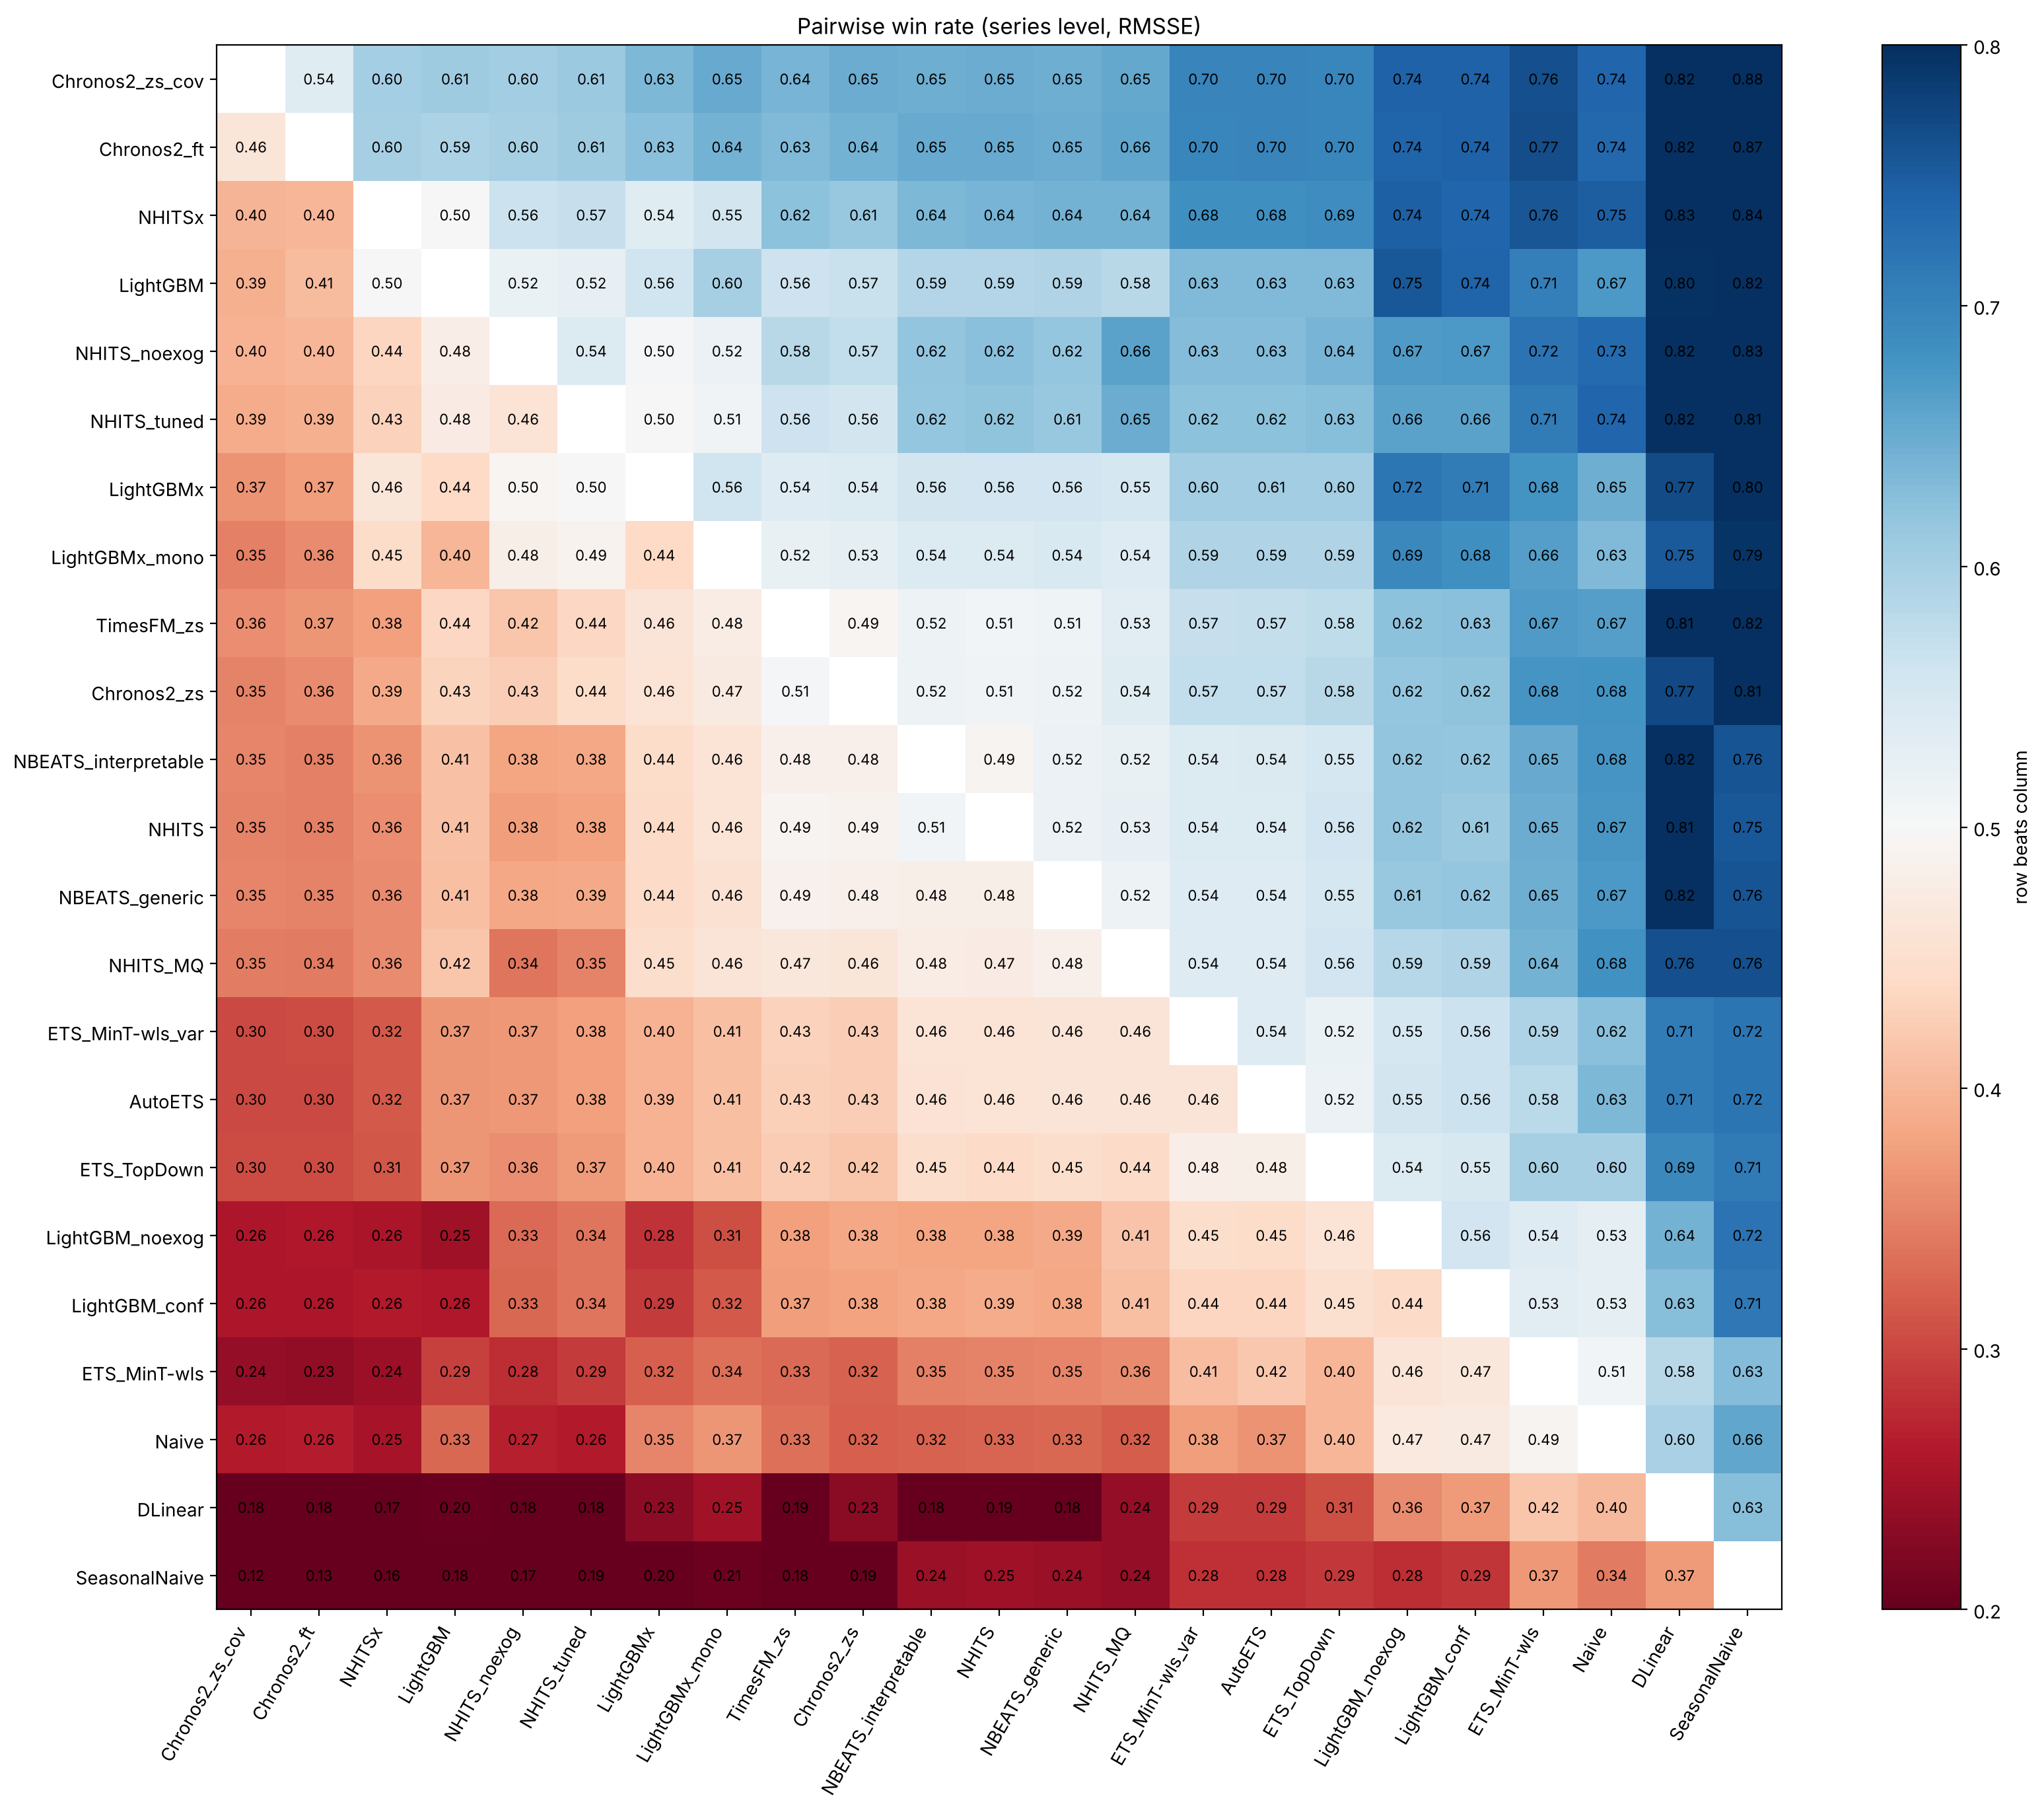

In [3]:
def win_matrix(R: pd.DataFrame) -> pd.DataFrame:
    a = R.values
    W = (a[:, :, None] < a[:, None, :]).mean(0) + 0.5 * (a[:, :, None] == a[:, None, :]).mean(0)
    np.fill_diagonal(W, np.nan)
    return pd.DataFrame(W, index=R.columns, columns=R.columns)

W = win_matrix(R)
order = W.mean(axis=1).sort_values(ascending=False).index
W = W.loc[order, order]
fig, ax = plt.subplots(figsize=(1 + 0.7 * len(models), 0.6 * len(models)))
im = ax.imshow(W, cmap="RdBu", vmin=0.2, vmax=0.8)
ax.set_xticks(range(len(order)), order, rotation=60, ha="right"), ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j:
            ax.text(j, i, f"{W.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="row beats column")
ax.set_title("Pairwise win rate (series level, RMSSE)")
plt.tight_layout()

## 2. Elo and Bradley–Terry

* **Bradley–Terry**: P(A beats B) = s_A / (s_A + s_B). Fit the strengths s by maximum likelihood on all
  pairwise wins (the classic MM algorithm, ~20 lines below).
* **Elo**: replay every series as a round-robin tournament in random order and update ratings after each duel.
  Order-dependent, so we average over shuffles. Popular in LLM arenas, and the same idea.

In [4]:
def bradley_terry(R: pd.DataFrame, iters: int = 500) -> pd.Series:
    a = R.values
    wins = (a[:, :, None] < a[:, None, :]).sum(0) + 0.5 * (a[:, :, None] == a[:, None, :]).sum(0)
    np.fill_diagonal(wins, 0)
    games = wins + wins.T
    s = np.ones(a.shape[1])
    for _ in range(iters):
        denom = (games / (s[:, None] + s[None, :])).sum(1)
        s_new = wins.sum(1) / denom
        s_new /= np.exp(np.log(s_new).mean())
        if np.allclose(s, s_new, rtol=1e-10):
            break
        s = s_new
    return pd.Series(400 * np.log10(s) + 1000, index=R.columns, name="bradley_terry")  # Elo-like scale


def elo(R: pd.DataFrame, k: float = 4.0, n_shuffles: int = 10, seed: int = 0) -> pd.Series:
    rng = np.random.default_rng(seed)
    a, m = R.values, R.shape[1]
    pairs = [(i, j) for i in range(m) for j in range(i + 1, m)]
    out = np.zeros(m)
    for _ in range(n_shuffles):
        r = np.full(m, 1000.0)
        for row in a[rng.permutation(len(a))]:
            for i, j in pairs:
                e = 1 / (1 + 10 ** ((r[j] - r[i]) / 400))
                s = 1.0 if row[i] < row[j] else 0.0 if row[i] > row[j] else 0.5
                r[i] += k * (s - e)
                r[j] -= k * (s - e)
        out += r
    return pd.Series(out / n_shuffles, index=R.columns, name="elo")


ratings = pd.concat([bradley_terry(R), elo(R), R.mean().rename("mean_rmsse"),
                     W.mean(axis=1).rename("avg_win_rate")], axis=1).sort_values("bradley_terry", ascending=False)
ratings.round(3)

,bradley_terry,elo,mean_rmsse,avg_win_rate
Chronos2_zs_cov,1130.175,1159.954,1.216,0.677
Chronos2_ft,1126.088,1162.756,1.205,0.672
NHITSx,1099.519,1117.794,1.228,0.637
LightGBM,1077.459,1067.395,1.274,0.608
NHITS_noexog,1075.329,1098.197,1.244,0.605
NHITS_tuned,1066.683,1088.712,1.252,0.593
LightGBMx,1053.683,1045.628,1.296,0.575
LightGBMx_mono,1038.525,1027.439,1.311,0.553
TimesFM_zs,1027.368,1038.953,1.316,0.537
Chronos2_zs,1027.153,1043.167,1.352,0.537


Do the rating order and the mean-RMSSE order agree? When they disagree, one model is winning **often but by
little**, the other **rarely but by a lot** on a few series (which drives the mean).

### Reading the result

In the reference run the two **Chronos-2** models with covariates lead both rankings: Chronos2_ft has the best
mean RMSSE on the common set (≈ 1.21), Chronos2_zs_cov the best Bradley–Terry rating (it wins 68 % of its duels),
then NHITSx. Below them the orders disagree: **LightGBM** is 6th on the mean (≈ 1.27) but 4th in the duels, ahead
of NHITS_noexog and NHITS_tuned. The reason is the ~2,900 intermittent series: 17 % of the panel, but 46–49 % of
the summed RMSSE. LightGBM wins many ordinary series by a little and loses some intermittent ones by a lot, so the
mean is mostly a contest about the hardest items.

*Reference run: all 17,241 eligible series, 4-core laptop CPU, 500 steps. Your numbers will differ a little; the
reading should not.*

## 3. Performance by volume and shape

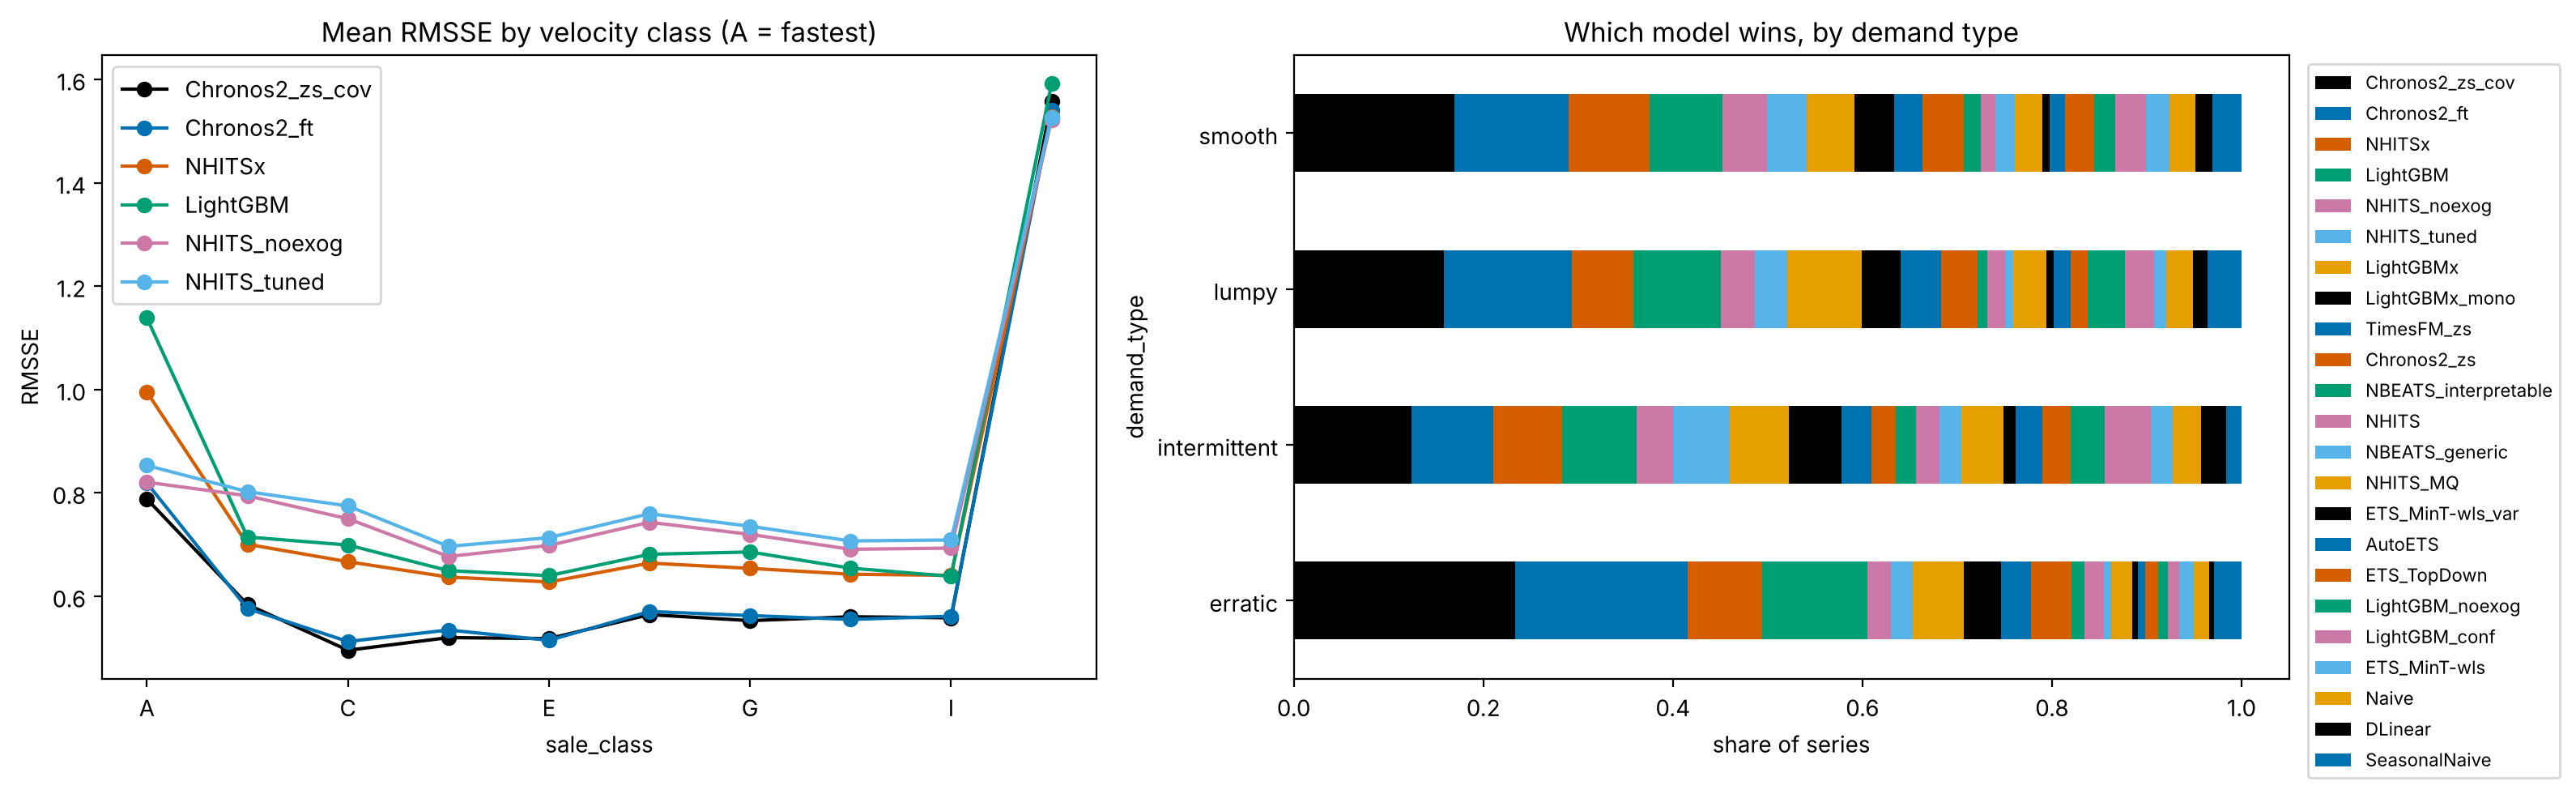

In [5]:
info = bc.series_info(panel).to_pandas().set_index("unique_id")
Rx = R.join(info)
best = Rx[models].idxmin(axis=1).rename("best_model")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
by_class = Rx.groupby("sale_class")[models].mean()
by_class[order[:6]].plot(marker="o", ax=axes[0])
axes[0].set_title("Mean RMSSE by velocity class (A = fastest)"), axes[0].set_ylabel("RMSSE")
pd.crosstab(Rx["demand_type"], best, normalize="index").reindex(columns=order, fill_value=0).plot.barh(stacked=True, ax=axes[1], legend=False)
axes[1].set_title("Which model wins, by demand type"), axes[1].set_xlabel("share of series")
axes[1].legend(bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

In [6]:
Rx.groupby("demand_type")[list(order[:6])].mean().round(3).assign(n=Rx.groupby("demand_type").size())

,Chronos2_zs_cov,Chronos2_ft,NHITSx,LightGBM,NHITS_noexog,NHITS_tuned,n
demand_type,,,,,,,
erratic,0.502,0.515,0.653,0.685,0.763,0.779,2284
intermittent,3.521,3.516,3.468,3.599,3.400,3.392,2906
lumpy,2.087,1.966,1.807,1.969,1.853,1.876,1475
smooth,0.613,0.611,0.655,0.664,0.668,0.678,10548


**Reading it.** No model wins everywhere. In the reference run Chronos-2 with covariates is best on **smooth**
(≈ 0.61) and, by a wide margin, on **erratic** series (≈ 0.50 vs ≈ 0.65 for NHITSx), where promotions explain the
spikes. NHITSx is best on **lumpy** series (≈ 1.81). On **intermittent** series (mostly zeros) the NHITS models
*without* covariates win (NHITS_tuned ≈ 3.39, NHITS_noexog ≈ 3.40) and Chronos-2 is among the worst of the top six
(≈ 3.52): there the covariates mostly give a model more ways to predict a spike that does not come. Errors on
intermittent series are about 5× larger than on smooth ones, whatever the model.

The cluster table below comes from Day 1's feature clustering. Several clusters hold only 1–7 series, so read
only the big ones.

In [7]:
Rx.groupby("cluster_label")[list(order[:6])].mean().round(3).assign(n=Rx.groupby("cluster_label").size())

,Chronos2_zs_cov,Chronos2_ft,NHITSx,LightGBM,NHITS_noexog,NHITS_tuned,n
cluster_label,,,,,,,
0,8.608,8.417,8.006,8.574,7.912,7.929,1212
1,0.609,0.610,0.656,0.640,0.710,0.714,8229
2,0.594,0.435,1.771,2.324,0.449,0.327,1
3,0.850,0.778,0.826,0.891,0.891,0.902,7
5,0.625,0.685,0.702,0.798,0.586,0.597,26
6,0.556,0.573,0.764,0.734,0.847,0.868,107
8,0.046,0.104,0.716,0.499,0.502,0.515,1
9,0.563,0.558,0.585,0.640,0.502,0.516,3328
10,0.571,0.572,0.686,0.689,0.801,0.819,1829


## 4. Ensembles

Choosing on the test window and then scoring on it is cheating. To stay honest without extra training runs we
use a **cross-sectional split**: half the series ("selection set") decide which models go in, the other half
("evaluation set") is scored. With more compute, the proper version uses a validation *time* window
(`bc.VALID_START`) for every model.

In [8]:
rng = np.random.default_rng(bc.RANDOM_SEED)
ids = R.index.to_numpy()
sel_ids = set(rng.choice(ids, size=len(ids) // 2, replace=False))
is_sel = R.index.isin(sel_ids)
R_sel, info_sel = R[is_sel], Rx[is_sel]

top3 = list(R_sel.mean().nsmallest(3).index)
seg_best = info_sel.groupby("sale_class")[models].mean().idxmin(axis=1).to_dict()   # per velocity class
print("top-3 on selection set:", top3)
print("per-class choice:", seg_best)

ens = fc[["unique_id", "ds"]].copy()
ens["ENS_mean_all"] = fc[models].clip(lower=0).mean(axis=1)
ens["ENS_median_all"] = fc[models].clip(lower=0).median(axis=1)
ens["ENS_mean_top3"] = fc[top3].clip(lower=0).mean(axis=1)
cls = ens.unique_id.map(info["sale_class"])
ens["SEL_by_class"] = [fc.at[i, seg_best.get(c, top3[0])] for i, c in zip(fc.index, cls)]

top-3 on selection set: ['Chronos2_zs_cov', 'Chronos2_ft', 'NHITSx']
per-class choice: {'A': 'NHITS_noexog', 'B': 'Chronos2_zs_cov', 'C': 'Chronos2_zs_cov', 'D': 'Chronos2_zs_cov', 'E': 'Chronos2_zs_cov', 'F': 'Chronos2_zs_cov', 'G': 'Chronos2_zs_cov', 'H': 'Chronos2_ft', 'I': 'Chronos2_zs_cov', 'J': 'NHITS_noexog'}


In [9]:
eval_mask = ~ens.unique_id.isin(sel_ids)
both = fc[["unique_id", "ds"] + models].merge(ens, on=["unique_id", "ds"])
eval_scores = bc.summarise(bc.score(both[eval_mask.values], test, train), both[eval_mask.values], test)
eval_scores[["model", "mean_rmsse", "median_rmsse", "wape", "bias_pct"]].head(12)

,model,mean_rmsse,median_rmsse,wape,bias_pct
0,ENS_mean_top3,1.219509,0.499879,0.220988,0.023409
1,SEL_by_class,1.248715,0.540810,0.227997,0.012340
2,Chronos2_ft,1.254591,0.515978,0.228961,0.022190
3,Chronos2_zs_cov,1.276709,0.512164,0.231110,0.025369
4,NHITSx,1.285701,0.577287,0.274421,0.022668
5,NHITS_noexog,1.299415,0.599852,0.289549,-0.031856
6,ENS_mean_all,1.301646,0.588719,0.294075,0.025371
7,NHITS_tuned,1.307324,0.599856,0.294443,-0.028544
8,ENS_median_all,1.327164,0.602661,0.291895,-0.008116
9,LightGBM,1.329872,0.570754,0.294151,0.114260


### Reading the result

![Lab 07 results](slides/img/res_lab07.png)

* On the held-out half, the plain **average of the top 3** (Chronos2_zs_cov, Chronos2_ft, NHITSx) beats every
  single model: ≈ 1.220 against ≈ 1.255 for the best single model on that half (Chronos2_ft), about 3 % better,
  and ≈ 8 % better than Day 1's LightGBM (≈ 1.330). Two of the three are the same Chronos-2, so most of the gain
  comes from mixing in NHITSx, a different model family that is better on lumpy and intermittent items.
* Picking the **best model per class** (≈ 1.249) lands between the two. It picks Chronos2_zs_cov for most
  classes and NHITS_noexog for the biggest and the slowest-selling ones (A and J), and still does not beat the
  plain average, which needs no choosing at all.
* The leaderboard below scores the ensembles on **all** series, half of which chose them, so their leaderboard
  numbers (≈ 1.164 for the top-3 average) are optimistic. Quote the held-out comparison.

*Reference run: all 17,241 eligible series, 4-core laptop CPU, 500 steps. Your numbers will differ a little; the
reading should not.*

Ensembles go on the leaderboard scored on **all** series, like everything else. The evaluation-set table above
is the fair comparison; check that the ranking agrees.

In [10]:
bc.save_forecasts(ens, "07_ensembles", actuals=test)
bc.save_raw(ens, "07_ensembles", "test", actuals=test)
bc.record(ens, test, train, lab="07 ensembles",
          notes=f"top3={top3}; selection on half the series")

,model,mean_rmsse,median_rmsse,mean_mase,median_mase,mean_smape,n_series,wape,bias_pct,lab,fit_seconds,notes,recorded_at
0,ENS_mean_top3,1.164025,0.497845,3.281600,0.524021,0.246489,17213,0.219341,0.022339,07 ensembles,None,"top3=['Chronos2_zs_cov', 'Chronos2_ft', 'NHITS...",2026-11-21 23:50:06
1,SEL_by_class,1.191901,0.539866,3.214836,0.562985,0.246224,17213,0.226149,0.010008,07 ensembles,None,"top3=['Chronos2_zs_cov', 'Chronos2_ft', 'NHITS...",2026-11-21 23:50:06
2,ENS_mean_all,1.255442,0.587098,3.416170,0.643990,0.266729,17213,0.295240,0.019989,07 ensembles,None,"top3=['Chronos2_zs_cov', 'Chronos2_ft', 'NHITS...",2026-11-21 23:50:06
3,ENS_median_all,1.270158,0.600548,3.403030,0.639073,0.270511,17213,0.294357,-0.014254,07 ensembles,None,"top3=['Chronos2_zs_cov', 'Chronos2_ft', 'NHITS...",2026-11-21 23:50:06


## 5. Final standings

In [11]:
board = bc.leaderboard()
cols = ["model", "lab", "mean_rmsse", "median_rmsse", "median_mase", "wape", "bias_pct", "fit_seconds"]
board[cols].round(3)

,model,lab,mean_rmsse,median_rmsse,median_mase,wape,bias_pct,fit_seconds
1,ENS_mean_top3,07 ensembles,1.164,0.498,0.524,0.219,0.022,NaN
2,SEL_by_class,07 ensembles,1.192,0.540,0.563,0.226,0.010,NaN
3,ENS_mean_all,07 ensembles,1.255,0.587,0.644,0.295,0.020,NaN
4,ENS_median_all,07 ensembles,1.270,0.601,0.639,0.294,-0.014,NaN
5,Chronos2_ft,04 foundation,1.282,0.516,0.537,0.228,0.020,971.147
6,Chronos2_zs_cov,04 foundation,1.294,0.511,0.530,0.229,0.023,363.446
7,NHITSx,03 exogenous,1.303,0.572,0.608,0.275,0.024,30.267
8,NHITS_noexog,03 exogenous,1.318,0.596,0.626,0.295,-0.035,27.177
9,NHITS_tuned,02 HPO,1.327,0.600,0.633,0.301,-0.032,538.412
10,LightGBM,00 day1 reference,1.354,0.569,0.627,0.291,0.114,5.598


### Every metric, every model

The full metric suite on the test window, from the raw forecasts every lab saved (`results/day2/raw/test/`),
including the prediction intervals of Labs 04 and 06. It is written to `results/day2/metrics_test.csv`.
Look for models whose rank changes with the metric: a model that wins on mean RMSSE but loses on bias or on
the intermittent items is a different choice for a buyer than for a planner.

In [12]:
raw = bc.load_raw("test", names=[p.stem for p in sorted((bc.RAW_DIR / "test").glob("*.parquet"))
                                  if p.stem != "05_hierarchy_all_levels"])
allfc = None
for name, f in raw.items():
    f = f.drop(columns=[c for c in f.columns if allfc is not None and c in allfc.columns and c not in ("unique_id", "ds")])
    allfc = f if allfc is None else allfc.merge(f, on=["unique_id", "ds"], how="outer")
complete = [m for m in bc.model_columns(allfc) if allfc[m].notna().mean() > 0.99]   # Lab 05 covers 17,216 items
suite = bc.metric_suite(allfc, bc.to_nixtla(train), models=complete, info=bc.series_info(panel))
suite.to_csv(bc.RESULTS_DIR / "metrics_test.csv", index=False)
pd.set_option("display.max_columns", 60)
suite.set_index("model").round(3)

metric_suite: TimesFM_zs's 95 % interval equals its 80 % interval; 95 % not scored


,mean_rmsse,median_rmsse,mean_mase,median_mase,mean_smape,avgrelmae,avgrelrmse,share_beats_baseline,mean_maape,mean_rmsle,pooled_wape,pooled_mae,pooled_rmse,bias_pct,share_series_over,rmsse_erratic,rmsse_intermittent,rmsse_lumpy,rmsse_smooth,coverage_80,scaled_winkler_80,scaled_width_80,coverage_95,scaled_winkler_95,scaled_width_95,scaled_crps
model,,,,,,,,,,,,,,,,,,,,,,,,,,
ENS_mean_top3,1.164,0.498,3.282,0.524,0.246,0.568,0.560,0.860,0.417,0.801,0.219,885.261,4518.341,0.022,0.500,0.501,3.431,1.852,0.587,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEL_by_class,1.192,0.540,3.215,0.563,0.246,0.601,0.602,0.834,0.412,0.797,0.226,912.739,4646.253,0.010,0.530,0.612,3.400,1.828,0.620,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENS_mean_all,1.255,0.587,3.416,0.644,0.267,0.693,0.663,0.780,0.465,0.910,0.295,1191.590,5318.663,0.020,0.472,0.698,3.514,1.847,0.671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENS_median_all,1.270,0.601,3.403,0.639,0.271,0.676,0.665,0.778,0.459,0.883,0.294,1188.024,5627.909,-0.014,0.524,0.740,3.500,1.866,0.687,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Chronos2_ft,1.282,0.516,3.827,0.537,0.243,0.581,0.581,0.851,0.399,0.830,0.228,918.356,4455.933,0.020,0.499,0.515,3.938,1.997,0.611,0.798,30.960,1.857,0.974,382.966,3.751,5.833
Chronos2_zs_cov,1.294,0.511,3.865,0.530,0.245,0.572,0.575,0.857,0.398,0.817,0.229,923.391,5756.153,0.023,0.504,0.502,3.946,2.118,0.613,0.767,31.311,1.710,0.966,358.465,3.451,5.610
NHITSx,1.303,0.572,3.746,0.608,0.258,0.657,0.646,0.803,0.438,0.866,0.275,1110.740,5416.501,0.024,0.513,0.653,3.879,1.832,0.655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NHITS_noexog,1.318,0.596,3.700,0.626,0.257,0.655,0.659,0.794,0.435,0.803,0.295,1188.905,5754.734,-0.035,0.564,0.763,3.806,1.882,0.668,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NHITS_tuned,1.327,0.600,3.718,0.633,0.267,0.664,0.665,0.775,0.452,0.829,0.301,1214.662,5865.734,-0.032,0.552,0.779,3.799,1.901,0.678,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Rank of each model on a few metrics (1 = best): where the columns disagree, the metric is the decision.

In [13]:
rank_cols = {"mean_rmsse": True, "median_mase": True, "avgrelmae": True, "pooled_wape": True,
             "mean_maape": True, "rmsse_intermittent": True}
ranks = pd.DataFrame({c: suite.set_index("model")[c].rank(ascending=asc) for c, asc in rank_cols.items()})
ranks["abs_bias_pct"] = suite.set_index("model")["bias_pct"].abs().rank()
ranks.sort_values("mean_rmsse").astype(int)

,mean_rmsse,median_mase,avgrelmae,pooled_wape,mean_maape,rmsse_intermittent,abs_bias_pct
model,,,,,,,
ENS_mean_top3,1,1,1,1,5,2,6
SEL_by_class,2,4,4,2,4,1,2
ENS_mean_all,3,10,12,9,15,4,5
ENS_median_all,4,9,8,7,12,3,3
Chronos2_ft,5,3,3,3,2,10,4
Chronos2_zs_cov,6,2,2,4,1,12,7
NHITSx,7,5,6,5,7,8,9
NHITS_noexog,8,6,5,8,6,6,12
NHITS_tuned,9,8,7,10,10,5,11


### Reading the result

* **Among single models the top is stable**: the two Chronos-2 models with covariates are the best two on mean
  RMSSE, median MASE, relative MAE, WAPE and MAAPE. (The ensemble rows are scored on all series, half of which
  chose them, so they are optimistic here as on the leaderboard.)
* **Intermittent items reorder everything.** On `rmsse_intermittent` Chronos-2 drops to 10th–12th and the NHITS
  models without covariates rise; this is the half of the error a buyer of slow movers cares about.
* **Bias is a separate axis.** LightGBM over-forecasts total volume by ≈ 11 % (≈ 12 % with covariates), the
  NHITS models without covariates under-forecast by ≈ 3 %, and NHITSx and Chronos-2 over-forecast by ≈ 2 %. A planner who pays for excess stock
  would read the leaderboard differently from one who pays for lost sales.
* TimesFM's 95 % interval is not scored: TimesFM 2.5 only predicts the 10 %, ..., 90 % quantiles, and
  timecopilot returns its 80 % interval when asked for 95 % (the suite detects this and says so above).

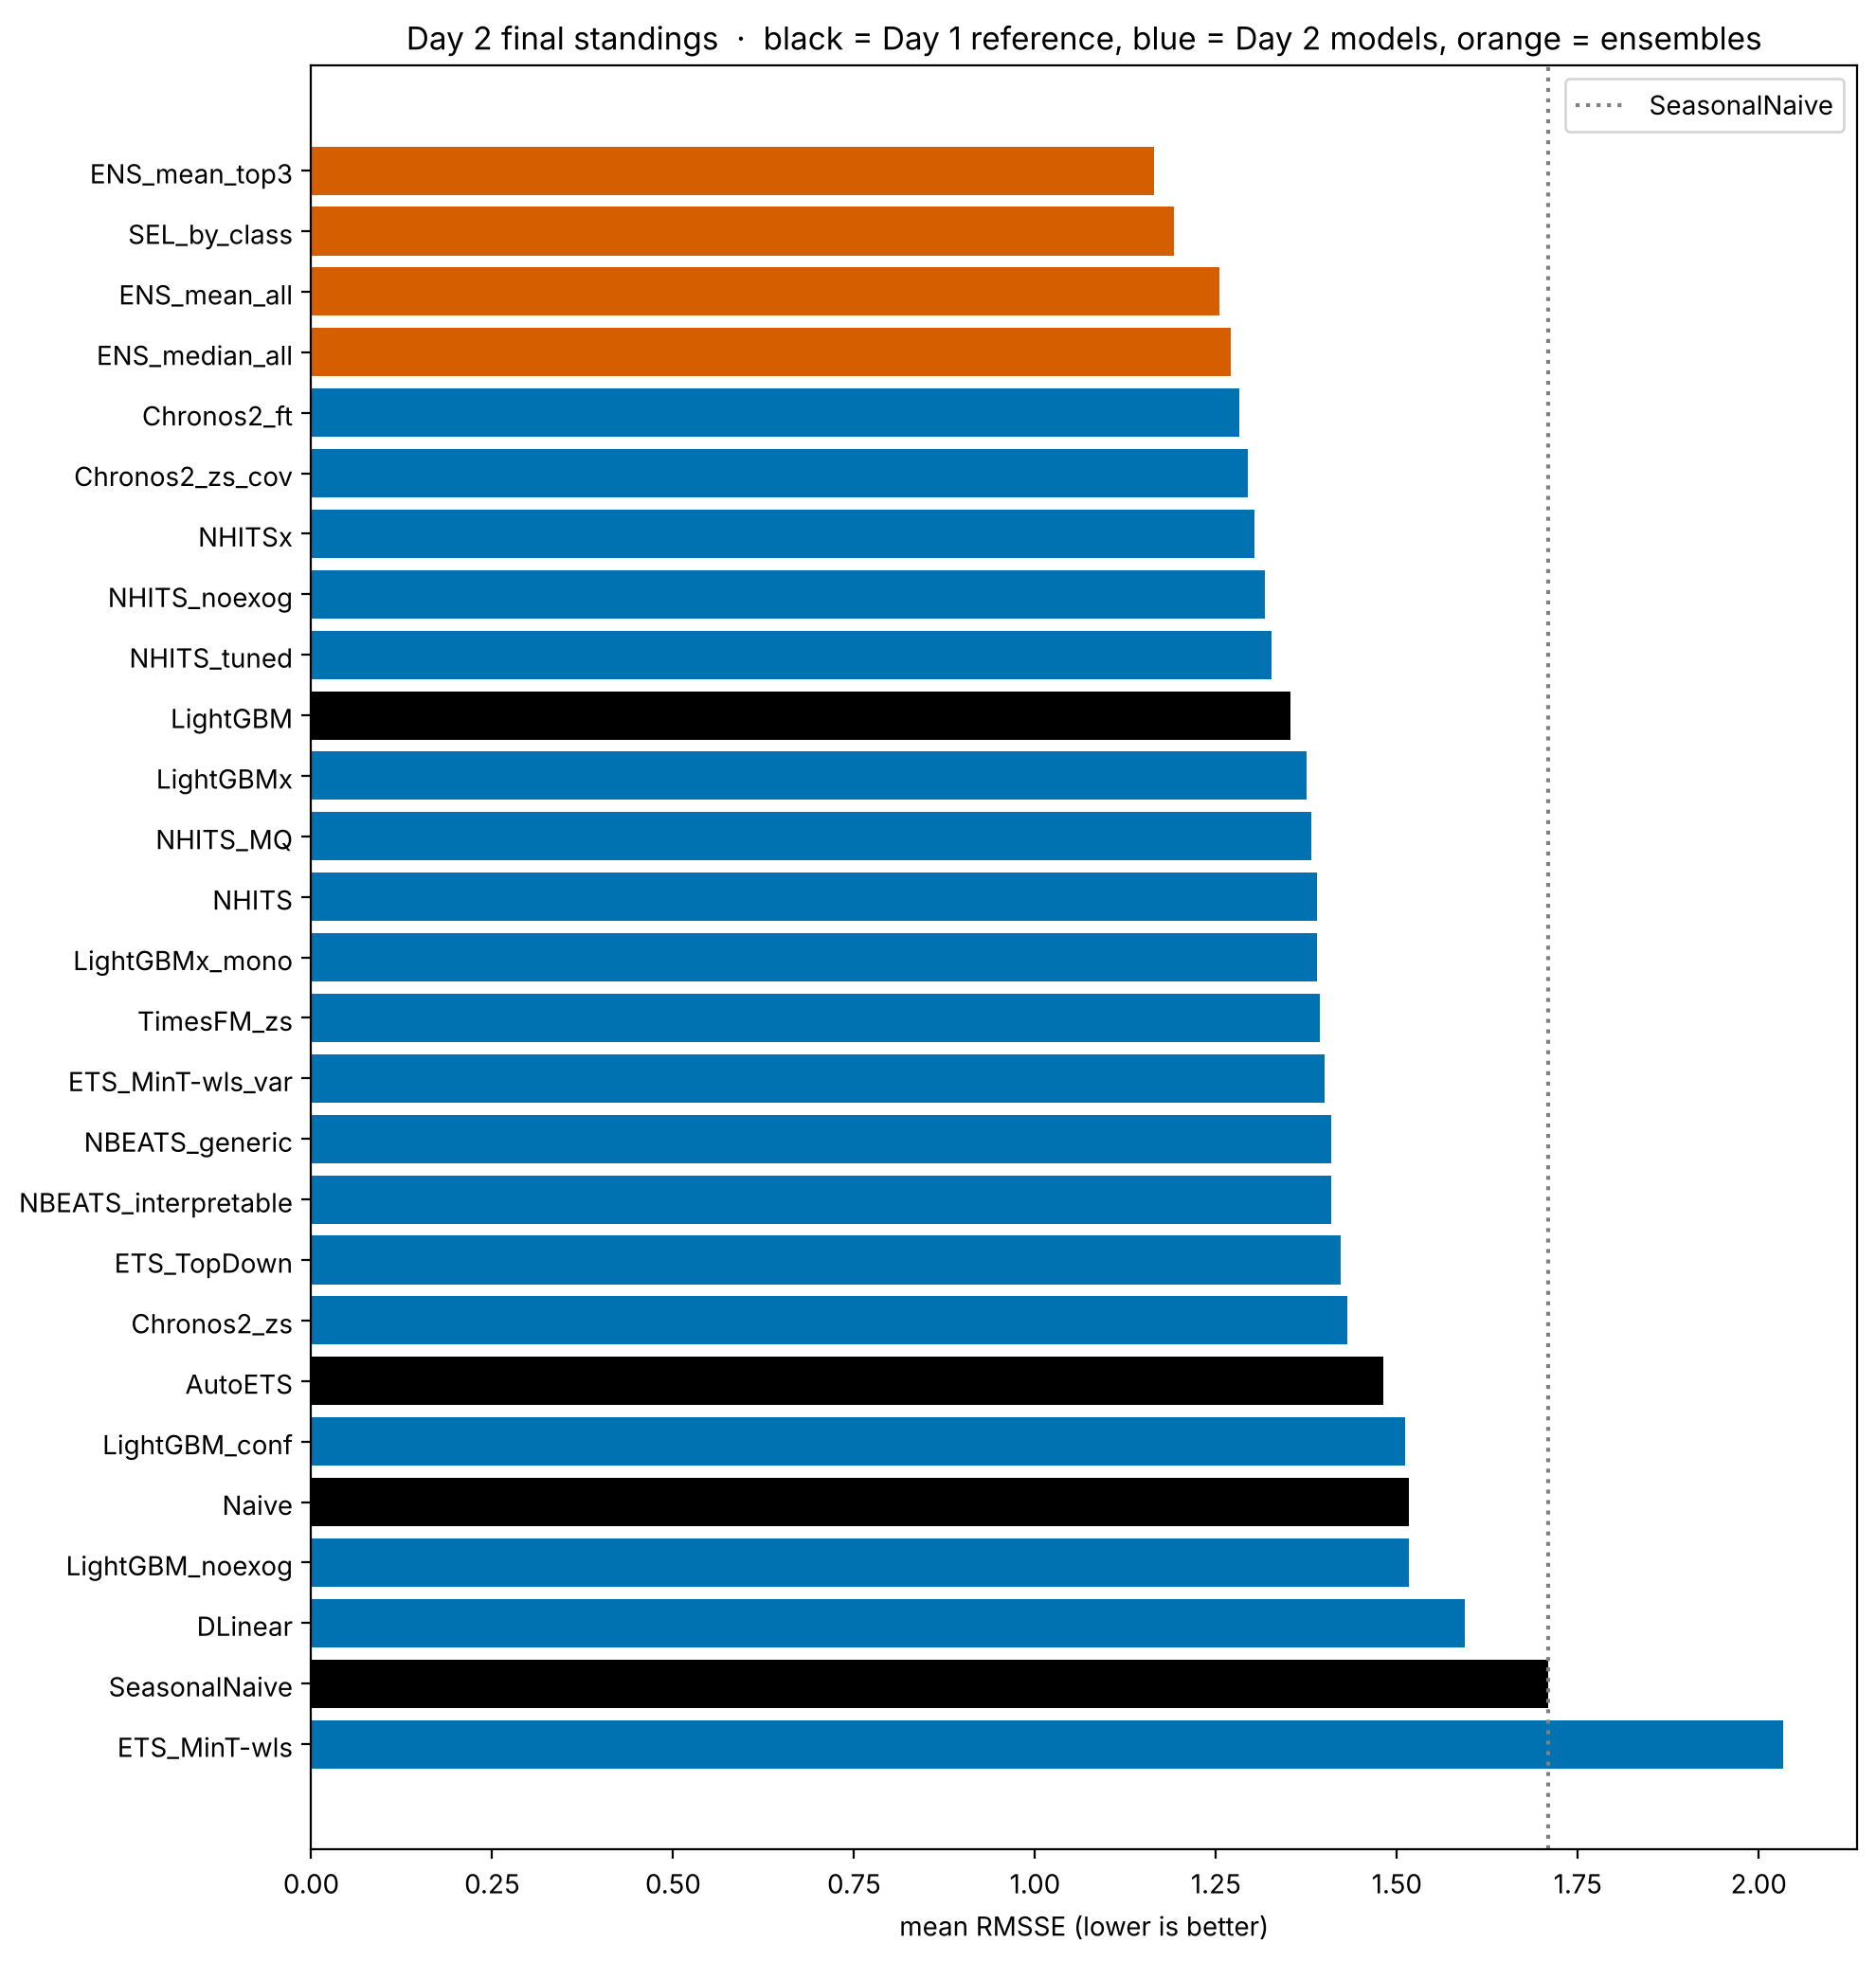

In [14]:
fig, ax = plt.subplots(figsize=(10, 0.35 * len(board) + 1))
colors = [palette[2] if str(l).startswith("07") else palette[1] if str(l).startswith(("0", "day2")) and not str(l).startswith("00")
          else palette[0] for l in board["lab"]]
ax.barh(board["model"][::-1], board["mean_rmsse"][::-1], color=colors[::-1])
snaive = board.loc[board.model == "SeasonalNaive", "mean_rmsse"]
if len(snaive):
    ax.axvline(snaive.iloc[0], color="grey", ls=":", label="SeasonalNaive")
    ax.legend()
ax.set_xlabel("mean RMSSE (lower is better)")
ax.set_title("Day 2 final standings  ·  black = Day 1 reference, blue = Day 2 models, orange = ensembles")
plt.tight_layout()
plt.savefig(bc.RESULTS_DIR / "final_standings.png", dpi=150)

### This morning's questions, answered

| Question from the recap | What today's numbers say (reference run) |
|---|---|
| Is the GBDT strong because it is **global** or because of **covariates**? | **Covariates**: LightGBM without them falls to ≈ 1.52, no better than Naive. NHITS without covariates (≈ 1.32) already beats LightGBM (≈ 1.35) |
| Can a neural net learn the hand-built features? | **Mostly yes**, from the raw window; covariates still help it on most series, just not on intermittent ones |
| What does it cost? | 19–27 s per neural fit vs ≈ 6 s; tuning ≈ 540 s for 4.5 %; a zero-shot foundation model ≈ 6 min on a CPU for all series, no training |
| Does it **respond to price** the right way? | **Direction yes, size timid**: promo lift +37 % to +57 % vs +82 % raw in the data (an upper bound) |
| Best single model? | **Zero-shot Chronos-2 with the price and promo calendar** (≈ 1.29 on all series, vs ≈ 1.30 for NHITSx and ≈ 1.35 for LightGBM); fine-tuning adds ≈ 0.01, inside the seed noise |
| Best of the day? | The **average of the top 3**: on the held-out half ≈ 1.22 vs ≈ 1.26 for the best single model and ≈ 1.33 for Day 1's LightGBM |

## A decision framework to take home

1. **Baselines first.** If you cannot beat SeasonalNaive / ETS on most series, stop and look at the data.
2. **Global before deep.** A GBDT with lags and covariates is the bar. A neural model has to beat it by more
   than the seed-to-seed noise (Lab 02), on more than one window, to justify its training and serving cost.
3. **Tune the few things that matter** (lookback, learning rate / steps, scaler, loss) and stop.
4. **Check responsiveness** before accuracy if the forecast drives pricing or promotion decisions.
5. **Foundation models** are a strong zero-shot baseline; fine-tune only when you have the data and the
   inference budget, and it beats your tuned global model on validation.
6. **Reconcile** when several levels are consumed; pick the method by the level that matters.
7. **Report win rates and segment results**, not only a mean, and **ensemble** when no single model dominates.